# 05 · Clasificación y Bayes: qué muestras vigilar y cuánto creerle a un positivo

Dos partes que se apoyan una en la otra. En la parte A se modela, con los mismos tres niveles de la
etapa 04, la probabilidad de que una muestra aceptada termine no conforme, vista desde la recepción,
y se fija un umbral de alerta por costo. En la parte B se responde la pregunta original del
laboratorio, la probabilidad de que un positivo sea falso, combinando la fiabilidad de cada ensayo
(sus controles de calidad) con el riesgo previo de cada muestra que entrega el clasificador.

← Anterior: [04 · Regresión](04_regresion.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [06 · Agrupamiento](06_agrupamiento.ipynb) →

## Código del proyecto

La celda siguiente recrea el paquete `proyecto/` dentro de la sesión, de forma que el notebook funciona en Google Colab sin clonar ningún repositorio: basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo. La sección puede plegarse desde su título. Trae también los guiones de las etapas anteriores: si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (49 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 4 etapas previas (se reconstruyen si faltan);
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (64 archivos, 181 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="0806094c1ffb9168cbd3f17829d429237e4a34482d1d773aba622e586dba55df",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import clasificacion

iniciar_etapa("05_clasificacion_bayes")
c = clasificacion.iniciar()
mostrar(c.encabezado)

## Parte A · Clasificación

## 1. El problema, la decisión y sus costos

El costo de cada error se fija antes de ver resultados, porque de él depende el umbral y no al revés.
Con una clase positiva tan escasa la exactitud engaña, de forma que se usan el ROC-AUC (probabilidad
de que una no conforme reciba más riesgo que una conforme), la precisión media (área bajo la curva
precisión-recall, cuya referencia es la prevalencia) y el Brier (error cuadrático de la probabilidad,
que premia la calibración), frente a un `Dummy` que predice la proporción del entrenamiento.

In [2]:
clasificacion.planteamiento(c).mostrar()

## 2. Pasada didáctica: los modelos del curso

Cada modelo usa el grupo ampliado y el preprocesamiento por defecto (imputación por la mediana,
estandarización y one-hot), sin afinar, en los mismos bloques temporales.

### 2.1 Árbol de clasificación con poda por costo-complejidad

In [3]:
clasificacion.poda(c).mostrar()

ccp_alpha,Hojas,ROC-AUC medio,Desv. ROC-AUC
0.000000,546,0.610,0.015
0.000038,298,0.620,0.022
0.000053,227,0.620,0.028
0.000072,148,0.620,0.034
0.000122,52,0.639,0.011
0.001655,2,0.556,0.031


### 2.2 KNN, regresión logística, árbol podado y perceptrón, con sus curvas ROC

Modelo,ROC-AUC,± ROC-AUC,Precisión media,± Precisión media,Brier,± Brier,Habilidad (2·AUC − 1)
Dummy (proporción),0.5000,0.0000,0.0892,0.0131,0.0813,0.0110,0.0000
KNN,0.6337,0.0243,0.1647,0.0181,0.0808,0.0106,0.2673
Regresión logística,0.7025,0.0214,0.2539,0.0194,0.0754,0.0096,0.4049
Árbol podado,0.6386,0.0114,0.1775,0.0074,0.0849,0.0101,0.2771
Perceptrón multicapa,0.6921,0.0210,0.2354,0.0323,0.0761,0.0096,0.3843


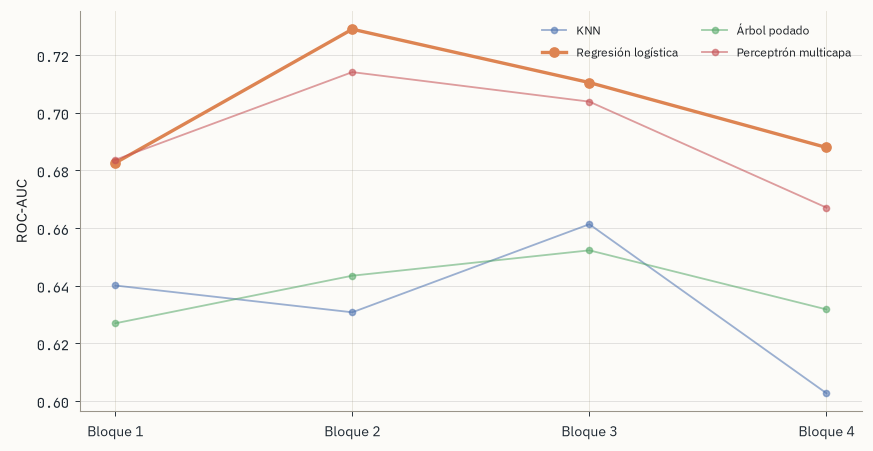

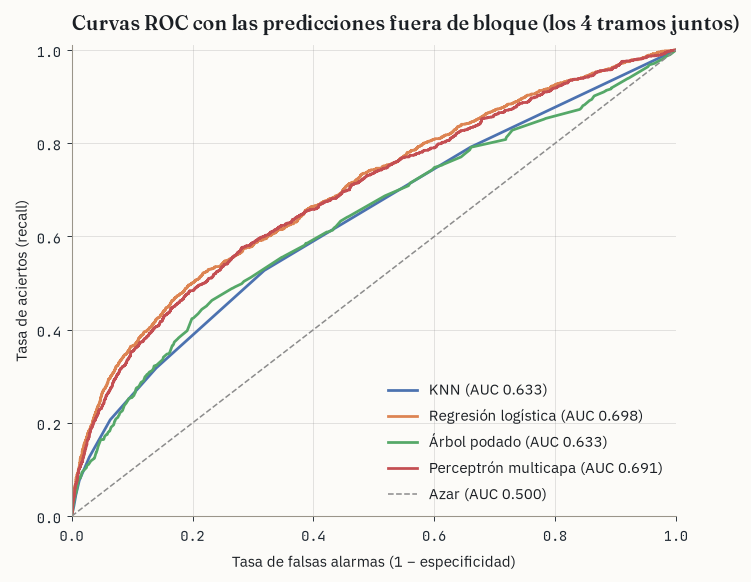

In [4]:
clasificacion.didactica(c).mostrar()

### 2.3 Qué dice la regresión logística

Con las numéricas estandarizadas, cada coeficiente es el cambio en el logaritmo de las odds de no
conformidad cuando la variable sube una desviación estándar, y su exponencial es la razón de odds
(1.5 significa odds un 50 % mayores).

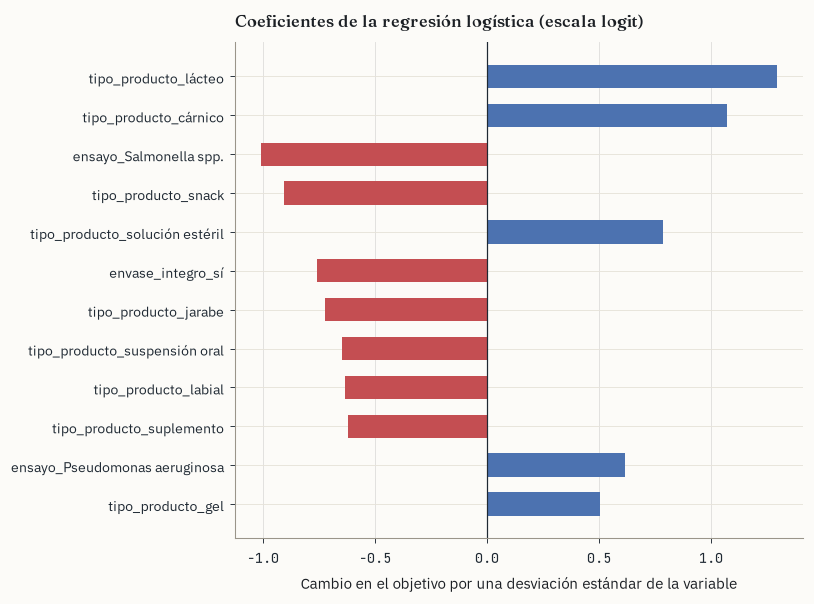

Variable,Coeficiente,Razón de odds
tipo_producto_lácteo,1.295,3.651
tipo_producto_cárnico,1.072,2.921
ensayo_Salmonella spp.,-1.011,0.364
tipo_producto_snack,-0.904,0.405
tipo_producto_solución estéril,0.783,2.188
envase_integro_sí,-0.758,0.468
tipo_producto_jarabe,-0.725,0.484
tipo_producto_suspensión oral,-0.648,0.523


In [5]:
clasificacion.logistica(c).mostrar()

### 2.4 Las reglas del árbol podado

Cada hoja es una conjunción de condiciones con la fracción de no conformes de las muestras de
entrenamiento que caen en ella; se muestran las de mayor riesgo.

In [6]:
clasificacion.reglas_arbol(c).mostrar()

Regla,Filas,Fracción de positivos
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas ≤ 26.31 y temperatura_por_horas > 22.47,22,0.773
historia_producto_tasa > 0.1178 y temperatura_por_horas > 298.8 y historia_producto_tasa > 0.1926,45,0.756
historia_producto_tasa > 0.1178 y temperatura_por_horas > 298.8 y historia_producto_tasa ≤ 0.1926 y historia_cliente_n_90 > 32 y volumen_ml ≤ 111,36,0.722
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas > 26.31 y tamano_lote > 4.5 y antiguedad_dias ≤ 1320,20,0.700
historia_producto_tasa ≤ 0.1178 y temperatura_por_horas > 293.2 y historia_producto_tasa > 0.0813 y actividad_agua > 0.9445 y horas_transporte ≤ 24.25,41,0.659
historia_producto_tasa > 0.1178 y temperatura_por_horas ≤ 298.8 y historia_producto_tasa > 0.185 y es_cuantitativo > 0.5 y ph ≤ 6.815 y temperatura_por_horas ≤ 26.31 y temperatura_por_horas ≤ 22.47 y hora_recepcion > 13.57,20,0.650


## 3. Nivel 2: cribado de la tubería con un arreglo L16 de Taguchi

Los factores son el modelo, el escalado, el grupo de variables, el tratamiento del desbalance
(sobremuestreo de la clase minoritaria, solo al ajustar), la selección de variables y la
codificación; las 128 combinaciones se reducen a 16 con la misma asignación de columnas de la etapa
04. La respuesta es el ROC-AUC de cada bloque, resumido con la S/N «mayor es mejor»,
S/N = −10 · log10(media de 1 / AUC²).

In [7]:
clasificacion.diseno(c).mostrar()

Corrida,modelo,escalado,grupo,desbalance,seleccion,codificacion
1,knn,estandar,base,ninguna,ninguna,one_hot
2,knn,estandar,ampliado,sobremuestreo,26,ordinal
3,knn,minmax,base,ninguna,26,ordinal
4,knn,minmax,ampliado,sobremuestreo,ninguna,one_hot
5,logistica,estandar,base,sobremuestreo,ninguna,ordinal
6,logistica,estandar,ampliado,ninguna,26,one_hot
7,logistica,minmax,base,sobremuestreo,26,one_hot
8,logistica,minmax,ampliado,ninguna,ninguna,ordinal
9,arbol,estandar,base,sobremuestreo,26,one_hot
10,arbol,estandar,ampliado,ninguna,ninguna,ordinal


Factor 1,Factor 2,Columnas de la interacción,Confundida con
modelo,escalado,"ac, bc, abc",libre
modelo,grupo,"ad, bd, abd",desbalance
modelo,desbalance,"d, ad, bd",grupo
modelo,seleccion,"cd, bcd, abcd",codificacion
modelo,codificacion,"cd, acd, abcd",seleccion
escalado,grupo,cd,libre
escalado,desbalance,abcd,libre
escalado,seleccion,ad,libre
escalado,codificacion,bd,libre
grupo,desbalance,A,modelo


Corrida,modelo,escalado,grupo,desbalance,seleccion,codificacion,bloque_1,bloque_2,bloque_3,bloque_4,media,desv,sn,segundos
1,knn,estandar,base,ninguna,ninguna,one_hot,0.626,0.604,0.637,0.629,0.624,0.014,-4.10,1.2
2,knn,estandar,ampliado,sobremuestreo,26,ordinal,0.603,0.637,0.643,0.640,0.631,0.019,-4.01,1.6
3,knn,minmax,base,ninguna,26,ordinal,0.616,0.617,0.626,0.654,0.628,0.018,-4.05,1.1
4,knn,minmax,ampliado,sobremuestreo,ninguna,one_hot,0.603,0.614,0.632,0.608,0.614,0.013,-4.24,1.5
5,logistica,estandar,base,sobremuestreo,ninguna,ordinal,0.661,0.711,0.685,0.663,0.680,0.023,-3.36,1.5
6,logistica,estandar,ampliado,ninguna,26,one_hot,0.681,0.727,0.697,0.669,0.693,0.025,-3.19,1.0
7,logistica,minmax,base,sobremuestreo,26,one_hot,0.670,0.710,0.690,0.651,0.680,0.026,-3.36,0.9
8,logistica,minmax,ampliado,ninguna,ninguna,ordinal,0.680,0.726,0.701,0.672,0.695,0.024,-3.17,1.4
9,arbol,estandar,base,sobremuestreo,26,one_hot,0.618,0.676,0.639,0.657,0.647,0.024,-3.79,1.0
10,arbol,estandar,ampliado,ninguna,ninguna,ordinal,0.658,0.685,0.669,0.635,0.662,0.021,-3.59,1.3


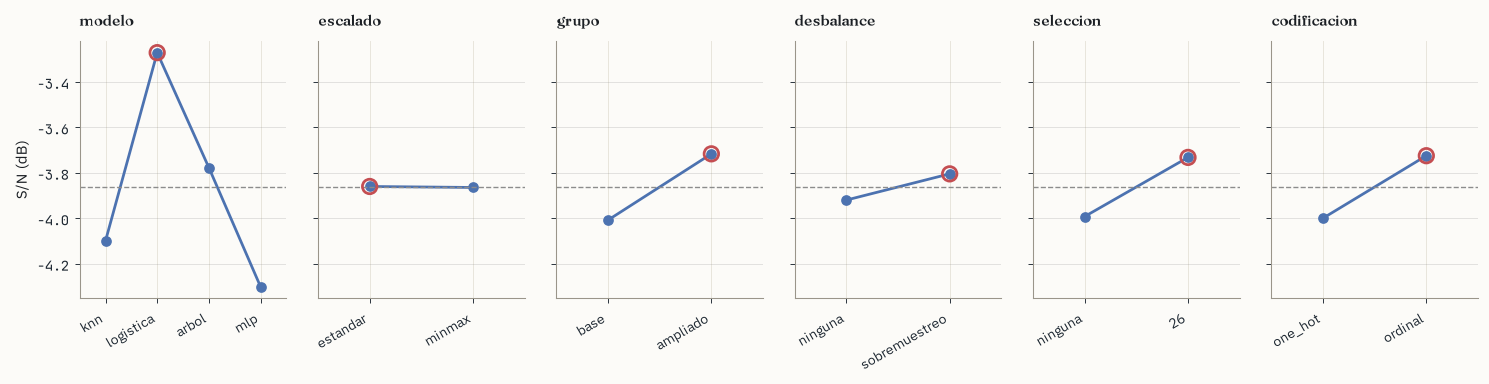

Factor,Mejor nivel,S/N mejor,Peor nivel,S/N peor,Delta,Rango
modelo,logistica,-3.272,mlp,-4.302,1.030,1
grupo,ampliado,-3.717,base,-4.008,0.292,2
codificacion,ordinal,-3.725,one_hot,-4.000,0.275,3
seleccion,26,-3.733,ninguna,-3.993,0.260,4
desbalance,sobremuestreo,-3.805,ninguna,-3.920,0.115,5
escalado,estandar,-3.860,minmax,-3.865,0.004,6


In [8]:
clasificacion.corridas_l16(c).mostrar()

### Comprobación dirigida: modelo × sobremuestreo

El sobremuestreo no afecta igual a todos los modelos: en el perceptrón con parada temprana, copias
de un mismo no conforme caen a la vez en su entrenamiento y en su validación interna; y en todos, al
igualar las clases, las probabilidades dejan de estar calibradas. Para separar esto de las
confusiones del L16, cada modelo didáctico se repite con sobremuestreo.

In [9]:
clasificacion.sobremuestreo(c).mostrar()

Modelo,AUC sin,AUC con,Δ AUC,Brier sin,Brier con,Prob. media sin,Prob. media con
KNN,0.634,0.615,-0.019,0.081,0.257,0.088,0.383
Regresión logística,0.702,0.699,-0.003,0.075,0.227,0.095,0.451
Árbol podado,0.639,0.597,-0.041,0.085,0.200,0.098,0.243
Perceptrón multicapa,0.692,0.612,-0.080,0.076,0.176,0.097,0.193


### Corrida de confirmación y factorial completo

In [10]:
clasificacion.confirmacion(c).mostrar()

## 4. Nivel 3: afinamiento de hiperparámetros

Como en la etapa 04: la configuración de mayor S/N observada y la segunda mejor familia de modelos,
con `GridSearchCV` en los mismos bloques y el ROC-AUC como métrica.

In [11]:
clasificacion.afinamiento(c).mostrar()

### Evaluación única en validación

Regla fijada antes de mirar: gana el mayor ROC-AUC de validación y, si la diferencia es menor que
0.005, el más sencillo (regresión logística, árbol, KNN, perceptrón).

In [12]:
clasificacion.evaluacion_validacion(c).mostrar()

Candidato,ROC-AUC,AUC inf.,AUC sup.,Precisión media,Brier
Regresión logística,0.7243,0.7008,0.7482,0.2582,0.2269
Árbol de decisión,0.6969,0.6721,0.7201,0.2035,0.2332
Dummy (proporción),0.5000,—,—,0.0893,0.0814


## 5. Calibración

El umbral teórico y la parte B suponen que una probabilidad de 0.2 significa que unas veinte de
cada cien muestras así salen no conformes. La versión calibrada usa `CalibratedClassifierCV` con el
método sigmoide (Platt, dos parámetros, adecuado con pocos no conformes por tramo) y los mismos
bloques temporales como `cv`. Regla: se usa la calibrada si la tubería sobremuestrea o si su Brier de
validación es menor.

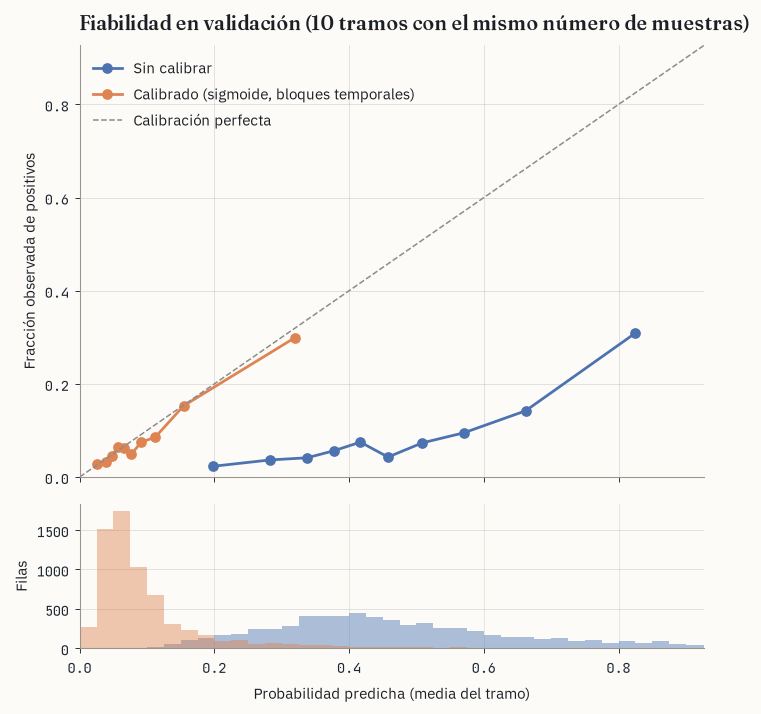

In [13]:
clasificacion.calibracion(c).mostrar()

## 6. Umbral por costo en validación

Se recorren umbrales de 0.02 a 0.50 (más el teórico) y se elige el de menor costo, desempatando
hacia el más alto. Al lado del costo van siempre la precisión, el recall y las alertas por semana,
que es la carga real que recibe el laboratorio.

Umbral,Alertas,Alertas por semana,Precisión,Recall,FP,FN,Costo
0.020,6446,238.7,0.090,0.990,5867,6,5897
0.040,5511,204.1,0.101,0.949,4956,30,5106
0.060,3988,147.7,0.120,0.819,3509,106,4039
0.080,2778,102.9,0.148,0.704,2366,173,3231
0.100,1994,73.9,0.177,0.603,1641,232,2801
0.120,1430,53.0,0.215,0.525,1123,278,2513
0.140,1114,41.3,0.246,0.468,840,311,2395
0.160,898,33.3,0.266,0.409,659,346,2389
0.167,843,31.2,0.275,0.397,611,353,2376
0.180,732,27.1,0.288,0.361,521,374,2391


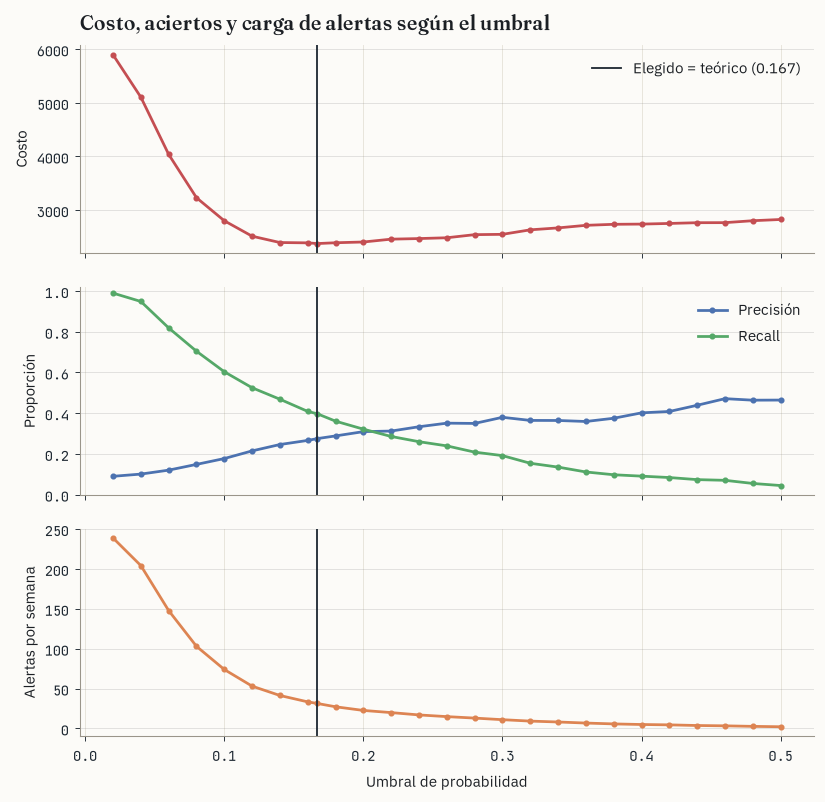

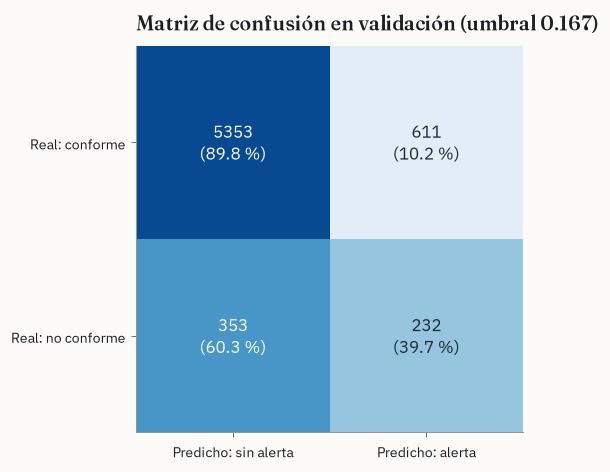

In [14]:
clasificacion.umbral_por_costo(c).mostrar()

## 7. Congelamiento del modelo

Hiperparámetros, configuración, calibración y umbral quedan fijos; el modelo se reajusta con
entrenamiento y validación (si va calibrado, con bloques temporales de todo el desarrollo).

In [15]:
clasificacion.congelar(c).mostrar()

## Parte B · Bayes: ¿qué tan probable es que un positivo sea un falso positivo?

## 8. La idea en palabras y en fórmulas

Un ensayo se describe con su **sensibilidad** s (fracción de contaminadas que da positivo, medida
con controles positivos) y su **especificidad** e (fracción de limpias que da negativo, medida con
controles negativos). Con la **prevalencia** π, el teorema de Bayes da el valor predictivo positivo:

$$\text{VPP} = P(\text{contaminada} \mid +) = \frac{s\,\pi}{s\,\pi + (1-e)(1-\pi)}, \qquad
P(\text{falso positivo} \mid +) = 1 - \text{VPP}.$$

Con prevalencia baja, el término (1 − e)(1 − π) pesa mucho aunque 1 − e sea pequeño: con e = 0.98,
π = 0.05 y s ≈ 0.95, más de una de cada cuatro alarmas es falsa. La prevalencia no se observa; se
observa la tasa de positivos p, y despejando π de p = s π + (1 − e)(1 − π) se obtiene la corrección
de Rogan–Gladen. Si una muestra se reensaya, el posterior del primer resultado hace de previa del
segundo.

## 9. Sensibilidad y especificidad de cada ensayo

Solo controles anteriores al periodo de prueba; intervalos de Wilson al 95 %.

In [16]:
clasificacion.sensibilidad_especificidad(c).mostrar()

Ensayo,Controles +,Sensibilidad,Sens. inf.,Sens. sup.,Controles −,Especificidad,Espec. inf.,Espec. sup.
Pseudomonas aeruginosa,1468,0.920,0.905,0.932,1468,0.986,0.978,0.991
Salmonella spp.,1468,0.897,0.881,0.912,1468,0.995,0.990,0.998
Staphylococcus aureus,1468,0.931,0.917,0.943,1468,0.990,0.983,0.994
coliformes y E. coli,1468,0.937,0.924,0.949,1468,0.980,0.972,0.986
esterilidad,1468,0.963,0.952,0.972,1468,0.980,0.972,0.986
mesófilos aerobios,1468,0.966,0.955,0.974,1468,0.977,0.968,0.983
mohos y levaduras,1468,0.950,0.938,0.960,1468,0.976,0.967,0.983


## 10. VPP por ensayo

La tasa de positivos sale de las muestras aceptadas del desarrollo. La incertidumbre se propaga
con sorteos de las posteriores Beta de sensibilidad, especificidad y tasa de positivos (previa
uniforme y sus conteos), con la semilla del proyecto.

Ensayo,Muestras,Positivos,Tasa de positivos,Sens.,Espec.,Prevalencia corregida,VPP,VPP inf.,VPP sup.,P(falso positivo)
Pseudomonas aeruginosa,2869,195,0.068,0.920,0.986,0.059,0.802,0.685,0.875,0.198
Salmonella spp.,520,23,0.044,0.897,0.995,0.044,0.897,0.761,0.956,0.103
Staphylococcus aureus,2684,100,0.037,0.931,0.990,0.029,0.734,0.543,0.842,0.266
coliformes y E. coli,4773,414,0.087,0.937,0.980,0.073,0.789,0.687,0.855,0.211
esterilidad,1366,70,0.051,0.963,0.980,0.033,0.627,0.428,0.759,0.373
mesófilos aerobios,10625,1071,0.101,0.966,0.977,0.082,0.789,0.702,0.849,0.211
mohos y levaduras,6175,632,0.102,0.950,0.976,0.085,0.787,0.701,0.850,0.213


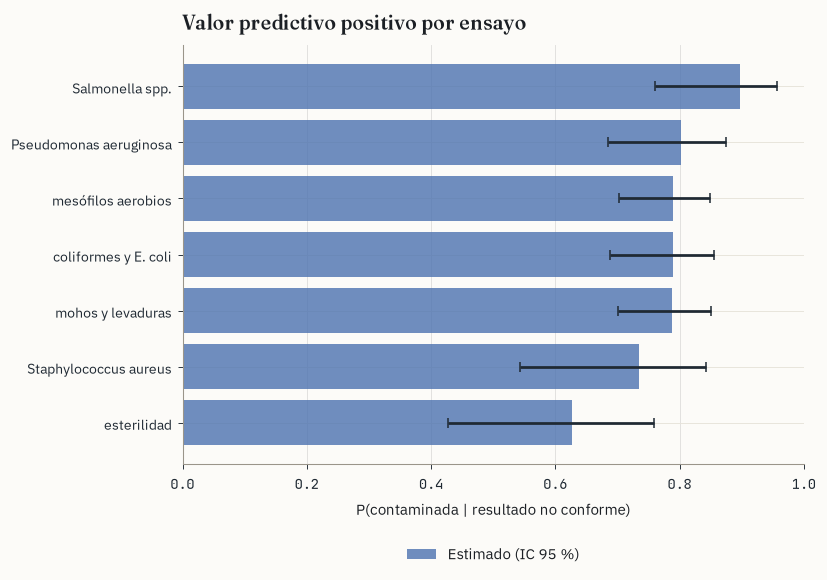

In [17]:
clasificacion.vpp_por_ensayo(c).mostrar()

## 11. VPP por muestra: la previa que aporta el clasificador

El clasificador estima p(x), la tasa de positivos esperada para muestras como x. Aplicando
Rogan–Gladen muestra a muestra se obtiene la previa π(x) y con ella VPP(x) = s · π(x) / p(x). Se
usa el modelo de la parte A ajustado solo con entrenamiento, sobre las muestras de validación.
π(x) = 0 significa que el positivo se explica entero por el error del ensayo.

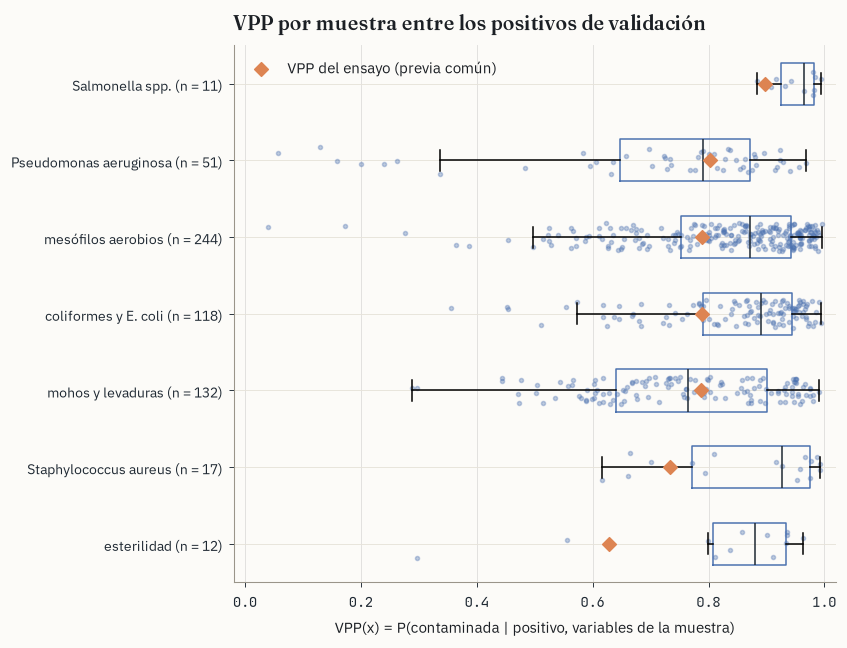

Ensayo,Positivos,VPP(x) medio,Percentil 10,Mediana,Percentil 90
Pseudomonas aeruginosa,51.000,0.715,0.262,0.791,0.923
Salmonella spp.,11.000,0.952,0.908,0.965,0.984
Staphylococcus aureus,17.000,0.862,0.663,0.926,0.989
coliformes y E. coli,118.000,0.849,0.661,0.890,0.967
esterilidad,12.000,0.811,0.581,0.879,0.935
mesófilos aerobios,244.000,0.826,0.623,0.871,0.973
mohos y levaduras,132.000,0.761,0.565,0.765,0.951


In [18]:
clasificacion.vpp_por_muestra(c).mostrar()

## 12. Posterior tras el reensayo

Con dos positivos la confianza sube; con un positivo y un negativo, baja (suponiendo resultados
independientes dada la condición real). El modelo predice además la fracción de reensayos
conformes, P(− | + inicial) = VPP · (1 − s) + (1 − VPP) · e, que se compara con lo observado.

In [19]:
clasificacion.reensayo(c).mostrar()

Ensayo,VPP (un +),"Posterior (+, +)","Posterior (+, −)",Reensayados,Fracción reensayada,Reensayo conforme esperado,Reensayo conforme observado
Pseudomonas aeruginosa,0.802,0.996,0.248,176,0.903,0.260,0.284
Salmonella spp.,0.897,0.999,0.474,21,0.913,0.195,0.429
Staphylococcus aureus,0.734,0.996,0.161,89,0.890,0.314,0.337
coliformes y E. coli,0.789,0.994,0.193,363,0.877,0.256,0.231
esterilidad,0.627,0.988,0.059,62,0.886,0.388,0.484
mesófilos aerobios,0.789,0.994,0.115,927,0.866,0.233,0.227
mohos y levaduras,0.787,0.993,0.158,548,0.867,0.247,0.332


## 13. Auditoría de la simulación

Solo porque los datos son simulados existe una verdad oculta (qué muestra estaba de verdad
contaminada); con datos reales el reensayo es la única referencia, imperfecta.

Ensayo,Sens. estimada,Sens. real,Espec. estimada,Espec. efectiva real,Prevalencia corregida,Prevalencia real,VPP estimado,VPP real,Dentro del IC
Pseudomonas aeruginosa,0.920,0.920,0.986,0.984,0.059,0.059,0.802,0.795,sí
Salmonella spp.,0.897,0.900,0.995,0.992,0.044,0.033,0.897,0.739,no
Staphylococcus aureus,0.931,0.930,0.990,0.986,0.029,0.026,0.734,0.670,sí
coliformes y E. coli,0.937,0.940,0.980,0.980,0.073,0.075,0.789,0.802,sí
esterilidad,0.963,0.960,0.980,0.970,0.033,0.026,0.627,0.471,sí
mesófilos aerobios,0.966,0.970,0.977,0.979,0.082,0.083,0.789,0.795,sí
mohos y levaduras,0.950,0.950,0.976,0.970,0.085,0.076,0.787,0.696,no


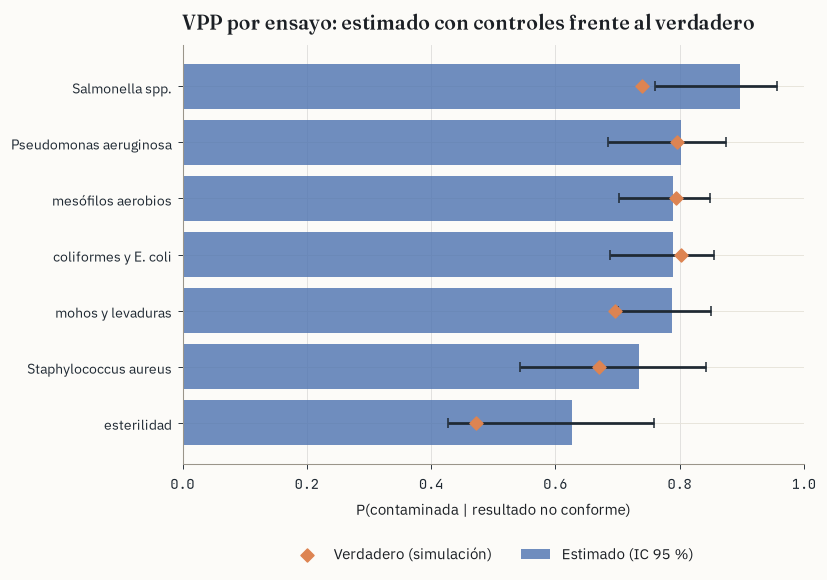

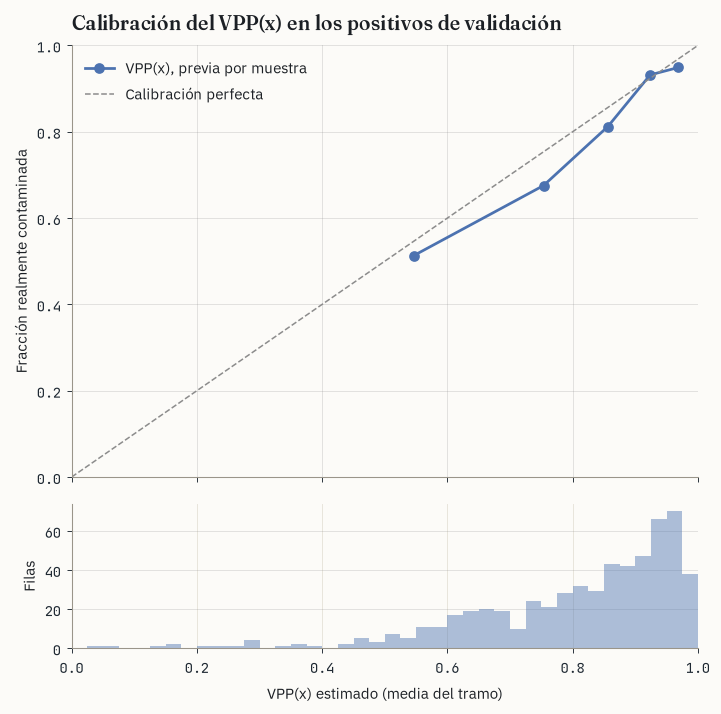

In [20]:
clasificacion.auditoria(c).mostrar()

## 14. Una regla simple para el reensayo

En la etapa 03, «falso positivo entre los no conformes» quedó fuera porque una sola variable, la
razón logarítmica entre el recuento y el límite, explicaba casi todo. Aquí se lee esa relación por
tramos con los no conformes reensayados del desarrollo.

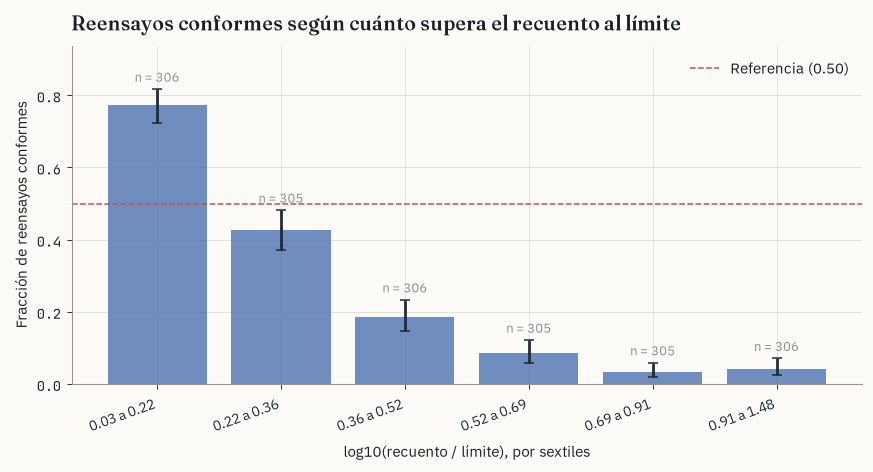

In [21]:
clasificacion.regla_reensayo(c).mostrar()

In [22]:
clasificacion.terminar(c)

← Anterior: [04 · Regresión](04_regresion.ipynb) &nbsp;·&nbsp; [Notebook completo](Proyecto_Final.ipynb) &nbsp;·&nbsp; Siguiente: [06 · Agrupamiento](06_agrupamiento.ipynb) →